# ParkVision AI — Intelligent Urban Parking Analytics

**Scenario 1 · UrbanFlow AI Pvt. Ltd. · CRS Artificial Intelligence — Machine Learning and Deep Learning**

This notebook walks through the complete system, end to end: the problem, the
data, the model, the insight logic, the evaluation and the deployed dashboard.

It **imports** the project's modules rather than re-implementing them, so every
number below is produced by exactly the code that runs in the Streamlit app.

| Step | Covered in |
|---|---|
| 1 · Understand the problem | §1 · [`docs/01_problem_definition.md`](../docs/01_problem_definition.md) |
| 2 · Data collection and preprocessing | §2 · [`src/data_prep.py`](../src/data_prep.py) |
| 3 · Model development | §3 · [`src/model.py`](../src/model.py) |
| 4 · Insight logic | §4 · [`src/insights.py`](../src/insights.py) |
| 5 · Streamlit dashboard | §5 · [`app.py`](../app.py) |
| 6 · Testing and feedback | §6 · [`scripts/04_robustness_test.py`](../scripts/04_robustness_test.py) |
| 7 · Deployment | §7 · [`docs/06_deployment.md`](../docs/06_deployment.md) |

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config as C
from src import insights as I
from src import layouts as L
from src import overlay as O
from src import slots as S

pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 110

print("project root:", ROOT)
print("image size  :", C.IMG_SIZE)
print("classes     :", C.CLASS_NAMES)

project root: C:\Users\Admin\Desktop\AI\SA 1\SA 1 Output
image size  : (224, 224)
classes     : ['empty', 'occupied']


---
## 1 · Understanding the problem

**Input** → one photograph of a parking lot from a fixed elevated camera, plus
that camera's surveyed bay layout.

**Output** → per-bay status (Occupied / Empty), total / occupied / available
counts, occupancy percentage, congestion level, and a recommendation.

The task is deliberately framed at **slot level**. A model that reports "this
lot looks busy" helps nobody; a driver needs a count, and a city needs a count
it can act on.

Congestion bands are fixed by the brief:

| Occupancy | Level |
|---|---|
| `< 40 %` | Low |
| `40 – 75 %` | Moderate |
| `> 75 %` | High |

In [2]:
# The decision rules are pure functions - no model needed to verify them.
for pct in [0, 12.5, 39.9, 40.0, 60.0, 75.0, 75.1, 92.0, 100.0]:
    print(f"{pct:6.1f}% occupancy  ->  {I.classify_congestion(pct)}")

   0.0% occupancy  ->  Low
  12.5% occupancy  ->  Low
  39.9% occupancy  ->  Low
  40.0% occupancy  ->  Moderate
  60.0% occupancy  ->  Moderate
  75.0% occupancy  ->  Moderate
  75.1% occupancy  ->  High
  92.0% occupancy  ->  High
 100.0% occupancy  ->  High


---
## 2 · Data collection and preprocessing

**Dataset — PKLot** (Almeida et al., *Expert Systems with Applications*, 2015):
12,417 photographs of three Brazilian parking lots, every five minutes, across
sunny, overcast and rainy days, with a hand-drawn quadrilateral and an
occupied/empty label for every bay.

Built by `python scripts/01_build_dataset.py`.

In [3]:
report = json.loads((C.RESULTS_DIR / "dataset_report.json").read_text(encoding="utf-8"))

print(f"source          : {report['source_dataset']}")
print(f"photographs     : {report['photographs_indexed']:,} indexed")
print(f"distinct scenes : {report['candidate_scenes']:,} kept after de-duplication")
print(f"scenes used     : {report['scenes_downloaded']}")
print(f"lots            : {report['lots']}")
print(f"weather         : {report['weather']}")
print(f"split strategy  : {report['split_strategy']}")
print()
print(pd.DataFrame(report["crops_per_split"]).T.rename_axis("split")
        .assign(total=lambda d: d.sum(axis=1)))
print(f"\ntotal slot crops: {report['total_crops']:,}  "
      f"({report['total_crops'] // len(C.CLASS_NAMES):,} per class)")

source          : PKLot (Almeida et al., 2015), Voxel51 mirror on Hugging Face
photographs     : 12,142 indexed
distinct scenes : 274 kept after de-duplication
scenes used     : 274
lots            : {'pucpr': 86, 'ufpr04': 88, 'ufpr05': 100}
weather         : {'sunny': 137, 'cloudy': 83, 'rainy': 54}
split strategy  : grouped by (lot, date) so no calendar day appears in two splits

       empty  occupied  total
split                        
train   2100      2100   4200
val      450       450    900
test     450       450    900

total slot crops: 6,000  (3,000 per class)


### 2.1 Exploratory analysis of the source dataset

`scene_summary.csv` holds one row per photograph, so the whole of PKLot can be
characterised before deciding what to sample from it.

12,142 photographs, 686,084 labelled bays



,filepath,lot,weather,date,time,n_spaces,n_occupied,occupancy_pct
0,data/data_0/2012-09-21_14_45_32.jpg,pucpr,sunny,2012-09-21,14:45:32,100,68,68.0
1,data/data_0/2012-09-21_15_30_34.jpg,pucpr,sunny,2012-09-21,15:30:34,100,67,67.0
2,data/data_0/2012-09-21_14_10_30.jpg,pucpr,sunny,2012-09-21,14:10:30,100,61,61.0
3,data/data_0/2012-09-21_16_25_36.jpg,pucpr,sunny,2012-09-21,16:25:36,100,65,65.0
4,data/data_0/2012-09-21_16_35_37.jpg,pucpr,sunny,2012-09-21,16:35:37,100,63,63.0


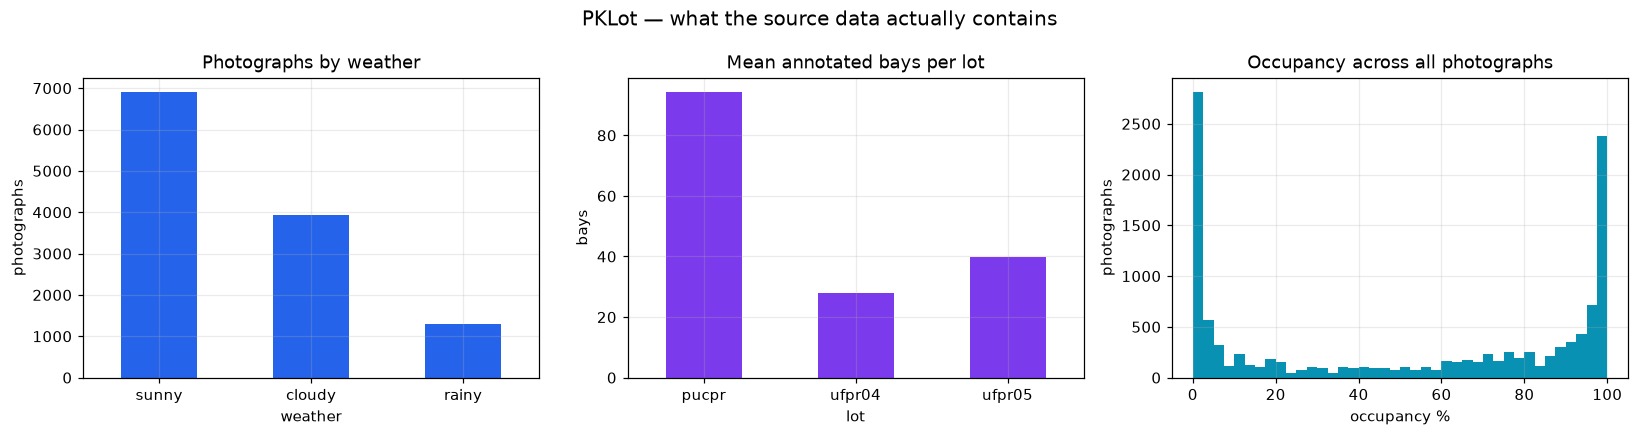

In [4]:
summary = pd.read_csv(C.RAW_DIR / "scene_summary.csv")
print(f"{len(summary):,} photographs, {summary['n_spaces'].sum():,} labelled bays\n")
display(summary.head())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

summary["weather"].value_counts().plot.bar(ax=axes[0], color="#2563EB", rot=0)
axes[0].set_title("Photographs by weather"); axes[0].set_ylabel("photographs")

summary.groupby("lot")["n_spaces"].mean().plot.bar(ax=axes[1], color="#7C3AED", rot=0)
axes[1].set_title("Mean annotated bays per lot"); axes[1].set_ylabel("bays")

axes[2].hist(summary["occupancy_pct"], bins=40, color="#0891B2")
axes[2].set_title("Occupancy across all photographs")
axes[2].set_xlabel("occupancy %"); axes[2].set_ylabel("photographs")

for ax in axes:
    ax.grid(alpha=.25)
fig.suptitle("PKLot — what the source data actually contains", fontsize=13)
fig.tight_layout(); plt.show()

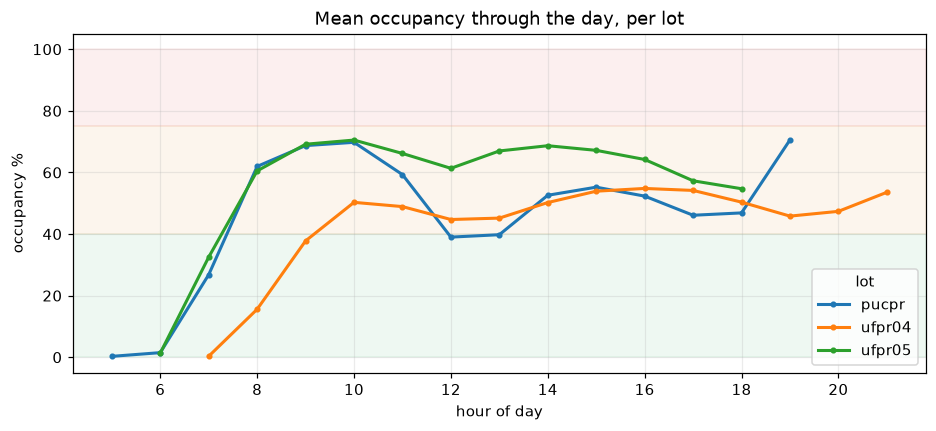

In [5]:
# Occupancy follows the working day: near-empty at dawn, full by early afternoon.
# This is exactly why crops are quota-filled class-balanced rather than sampled
# uniformly - uniform sampling would tie "empty" to "early morning light".
summary["hour"] = pd.to_datetime(summary["time"], format="%H:%M:%S").dt.hour
by_hour = summary.groupby(["lot", "hour"])["occupancy_pct"].mean().unstack(0)

ax = by_hour.plot(figsize=(10, 4), linewidth=2, marker="o", markersize=3)
ax.set_title("Mean occupancy through the day, per lot")
ax.set_xlabel("hour of day"); ax.set_ylabel("occupancy %")
ax.axhspan(0, 40, color="#16A34A", alpha=.07)
ax.axhspan(40, 75, color="#D97706", alpha=.07)
ax.axhspan(75, 100, color="#DC2626", alpha=.07)
ax.grid(alpha=.25); plt.show()

### 2.2 Perspective-correct cropping

Bays are quadrilaterals, not rectangles: an elevated camera projects a
rectangular bay to a trapezium. Cropping the axis-aligned bounding box would
pull in slices of both neighbours, so a car parked *next door* could make an
empty bay look occupied.

`src/slots.py` warps each quadrilateral to a 224×224 square instead, padded by
8% so an overhanging bumper stays inside the patch.

2012-09-12_09_08_18.jpg  -  PUCPR, cloudy, 100 bays, 95% occupied


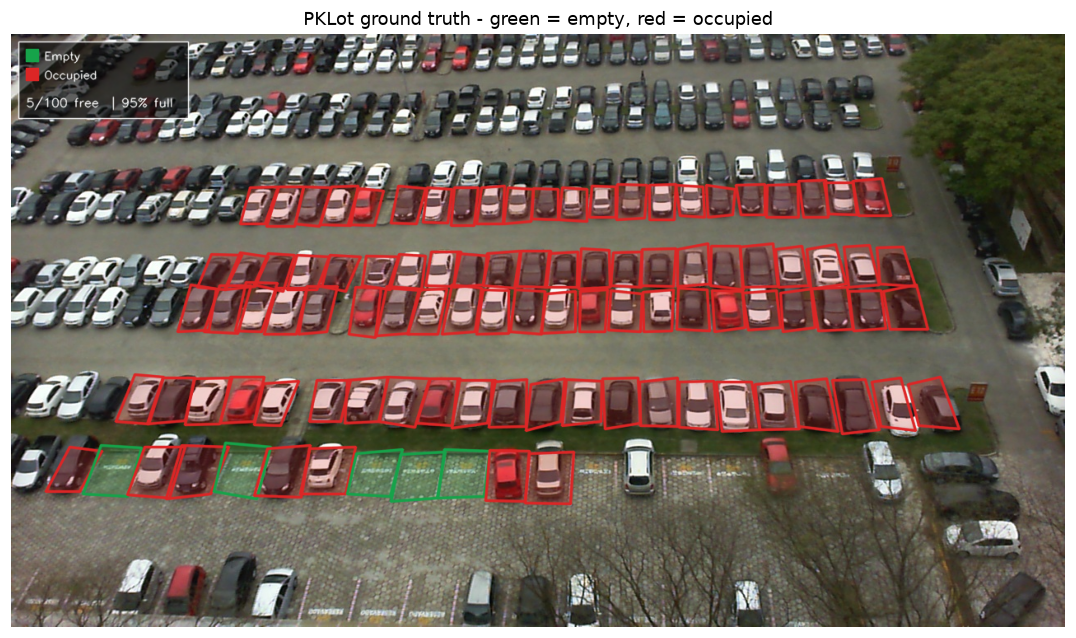

In [6]:
import cv2

demo = json.loads(C.DEMO_INDEX_PATH.read_text(encoding="utf-8"))
scene = max(demo, key=lambda e: e["n_spaces"])
image = cv2.cvtColor(cv2.imread(str(C.DEMO_DIR / scene["image"])), cv2.COLOR_BGR2RGB)
h, w = image.shape[:2]

print(f"{scene['image']}  -  {scene['lot'].upper()}, {scene['weather']}, "
      f"{scene['n_spaces']} bays, {scene['occupancy_pct_truth']:.0f}% occupied")

# Ground-truth geometry drawn on the full scene.
truth = [I.SlotPrediction(space_id=s["space_id"], status=s["label"],
                          confidence=1.0, score=float(s["label"] == "occupied"),
                          polygon=s["points"])
         for s in scene["spaces"]]

fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(O.annotate(image, truth, I.generate_insight(truth), mark_uncertain=False))
ax.set_title("PKLot ground truth - green = empty, red = occupied", fontsize=12)
ax.axis("off"); plt.show()

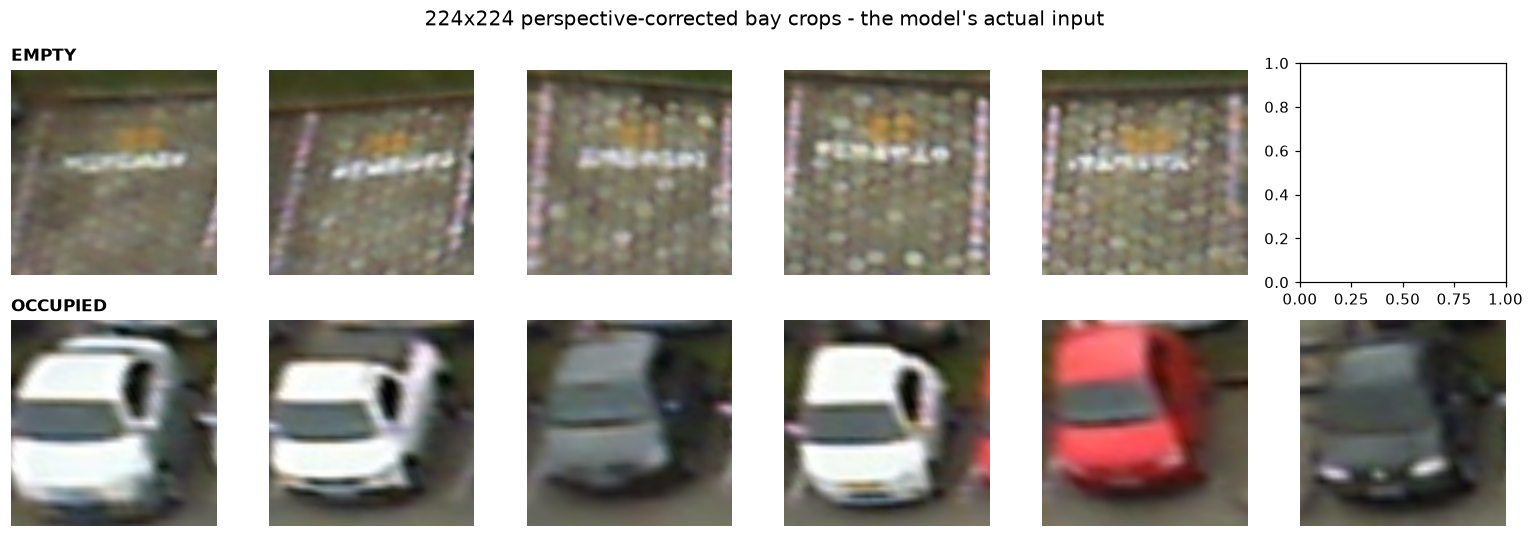

In [7]:
# The same bays, deskewed exactly as the model receives them.
empties  = [s for s in scene["spaces"] if s["label"] == "empty"][:6]
occupied = [s for s in scene["spaces"] if s["label"] == "occupied"][:6]

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for row, (group, name) in enumerate([(empties, "EMPTY"), (occupied, "OCCUPIED")]):
    for col, space in enumerate(group):
        polygon = S.polygon_to_pixels(space["points"], w, h)
        axes[row, col].imshow(S.crop_slot(image, polygon, C.IMG_SIZE))
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_ylabel(name)
    axes[row, 0].set_title(name, loc="left", fontsize=11, fontweight="bold")
fig.suptitle("224x224 perspective-corrected bay crops - the model's actual input", fontsize=13)
fig.tight_layout(); plt.show()

### 2.3 Augmentation

Applied to the **training split only**, as layers inside the model graph, so
each epoch sees fresh randomisation and the deployed model cannot accidentally
augment at inference time.

Vertical flip is deliberately excluded: it would put a car's roof where its
shadow belongs — something a fixed overhead camera can never produce.

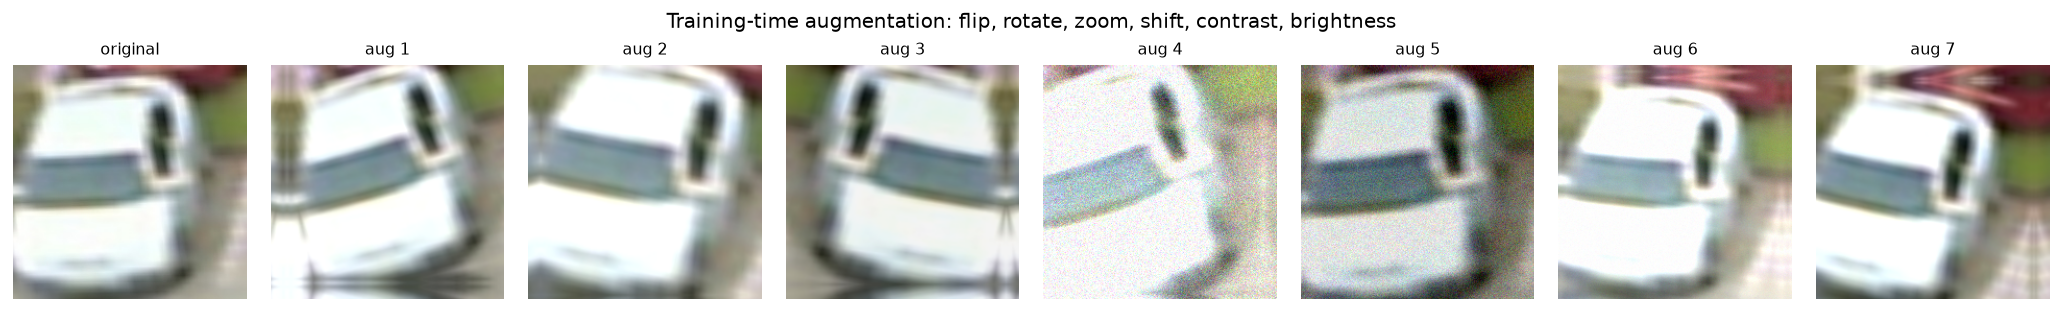

In [8]:
from IPython.display import Image as IPyImage
IPyImage(filename=str(C.RESULTS_DIR / "augmentation_examples.png"))

### 2.4 The split — and the leakage trap

PKLot frames are five minutes apart, so two frames of the same lot on the same
afternoon are near-identical. Splitting crops **at random** would put a crop and
its near-twin on opposite sides of the train/test boundary; the model could then
score ~99.9% on test by memorising, and the number would mean nothing.

Whole **`(lot, calendar date)`** groups are therefore assigned to a split.

In [9]:
manifest = pd.DataFrame(json.loads((C.PROCESSED_DIR / "manifest.json").read_text(encoding="utf-8")))

print("crops per split and class")
display(pd.crosstab(manifest["split"], manifest["label"], margins=True))

print("\nno calendar day is shared between splits:")
days = manifest.groupby(["lot", "date"])["split"].nunique()
print(f"  {(days > 1).sum()} of {len(days)} (lot, date) groups appear in more than one split")

print("\ncrops by weather and split")
display(pd.crosstab(manifest["weather"], manifest["split"]))

crops per split and class


label,empty,occupied,All
split,,,
test,450,450,900
train,2100,2100,4200
val,450,450,900
All,3000,3000,6000



no calendar day is shared between splits:
  0 of 98 (lot, date) groups appear in more than one split

crops by weather and split


split,test,train,val
weather,,,
cloudy,222,1547,100
rainy,157,768,222
sunny,521,1885,578


---
## 3 · Model development

**MobileNetV2** pre-trained on ImageNet, with the classifier head replaced by
global-average-pool → dropout → a single sigmoid unit.

Trained in two phases:

| Phase | Epochs | Learning rate | What trains |
|---|---|---|---|
| 1 | 12 | `1e-3` | The new head only; backbone frozen |
| 2 | 10 | `1e-5` | Head + MobileNetV2 from layer 100 up (BatchNorm stays frozen) |

Fine-tuning immediately would push the randomly initialised head's large
gradients straight into the pre-trained filters and destroy them, so the head
is stabilised first.

In [10]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
from src import inference as INF

# The shared loader registers the custom noise layer before loading.
model = INF.load_model(C.MODEL_PATH)
model.summary()

size_mb = C.MODEL_PATH.stat().st_size / 1e6
print(f"\nsaved model: {size_mb:.1f} MB  -  small enough for Streamlit Community Cloud")

Model: "parkvision_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ slot_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_backbone            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ occupancy (Dense)               │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,941,061 (22.66 MB)

 Trainable params: 1,840,897 (7.02 MB)

 Non-trainable params: 418,368 (1.60 MB)

 Optimizer params: 3,681,796 (14.04 MB)


saved model: 24.4 MB  -  small enough for Streamlit Community Cloud


{
  "backbone": "MobileNetV2 (ImageNet weights)",
  "epochs_head": 12,
  "epochs_finetune": 10,
  "epochs_run": 22,
  "batch_size": 32,
  "lr_head": 0.001,
  "lr_finetune": 1e-05,
  "fine_tune_from_layer": 100,
  "dropout": 0.3,
  "label_smoothing": 0.02,
  "total_parameters": 2259265,
  "best_val_accuracy": 0.9977777600288391,
  "best_val_auc": 0.9999926090240479,
  "best_val_loss": 0.0671529620885849,
  "training_minutes": 30.39,
  "seed": 42
}


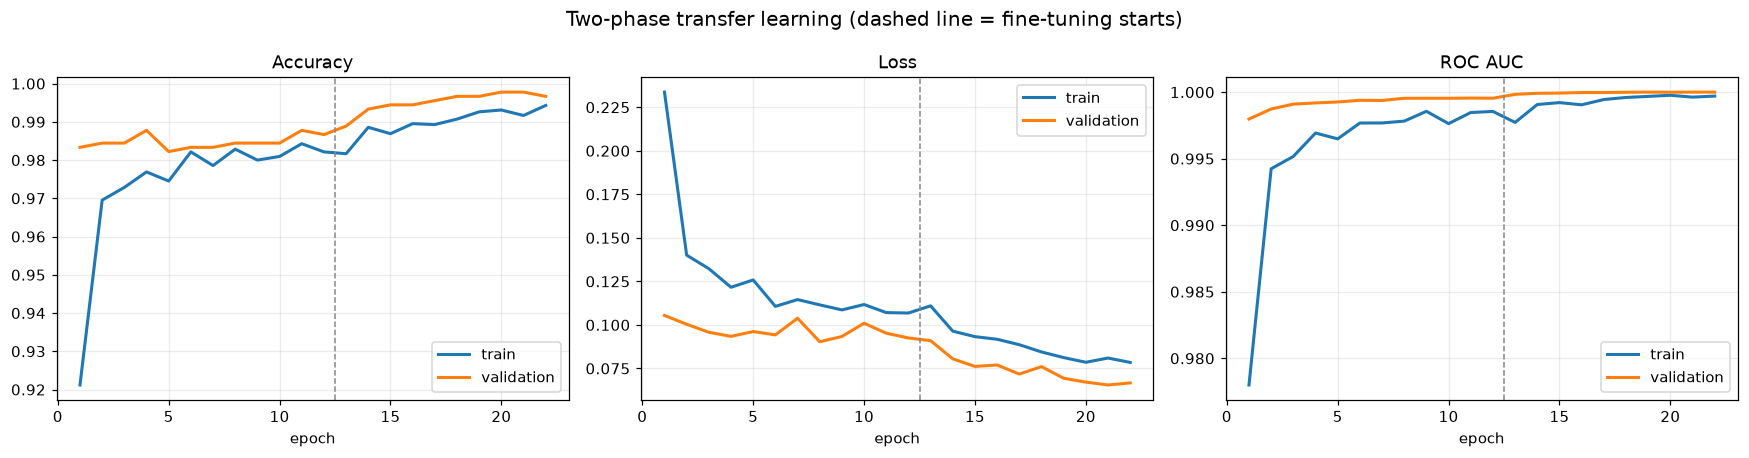

In [11]:
history = json.loads(C.HISTORY_PATH.read_text(encoding="utf-8"))
summary_json = json.loads((C.RESULTS_DIR / "training_summary.json").read_text(encoding="utf-8"))

print(json.dumps(summary_json, indent=2))

epochs = range(1, len(history["loss"]) + 1)
switch = summary_json["epochs_head"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (tr, va, title) in zip(axes, [("accuracy", "val_accuracy", "Accuracy"),
                                      ("loss", "val_loss", "Loss"),
                                      ("auc", "val_auc", "ROC AUC")]):
    ax.plot(epochs, history[tr], label="train", linewidth=2)
    ax.plot(epochs, history[va], label="validation", linewidth=2)
    ax.axvline(switch + .5, color="#888", linestyle="--", linewidth=1)
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=.25); ax.legend()
fig.suptitle("Two-phase transfer learning (dashed line = fine-tuning starts)", fontsize=13)
fig.tight_layout(); plt.show()

### 3.1 Evaluation

The decision threshold is swept over the **validation** split and then applied
**unchanged** to test. Tuning the threshold on test and reporting test accuracy
would be reporting a number we had fitted.

In [12]:
metrics = json.loads(C.METRICS_PATH.read_text(encoding="utf-8"))
test = metrics["test"]

print(f"operating threshold : {metrics['operating_threshold']:.2f} (chosen on validation)\n")
headline = pd.DataFrame({
    "metric": ["Accuracy", "Balanced accuracy", "Precision (occupied)",
               "Recall (occupied)", "F1 (occupied)", "ROC AUC",
               "Average precision", "Matthews corr."],
    "value":  [test["accuracy"], test["balanced_accuracy"], test["precision_occupied"],
               test["recall_occupied"], test["f1_occupied"], test["roc_auc"],
               test["average_precision"], test["matthews_corrcoef"]],
})
display(headline.style.format({"value": "{:.4f}"}).hide(axis="index"))
print(f"errors: {test['errors']} of {test['n_samples']} held-out bays")
print((C.RESULTS_DIR / "classification_report.txt").read_text(encoding="utf-8"))

operating threshold : 0.55 (chosen on validation)



metric,value
Accuracy,1.0000
Balanced accuracy,1.0000
Precision (occupied),1.0000
Recall (occupied),1.0000
F1 (occupied),1.0000
ROC AUC,1.0000
Average precision,1.0000
Matthews corr.,1.0000


errors: 0 of 900 held-out bays
ParkVision AI — test split classification report
decision threshold on P(occupied): 0.55

              precision    recall  f1-score   support

       Empty     1.0000    1.0000    1.0000       450
    Occupied     1.0000    1.0000    1.0000       450

    accuracy                         1.0000       900
   macro avg     1.0000    1.0000    1.0000       900
weighted avg     1.0000    1.0000    1.0000       900



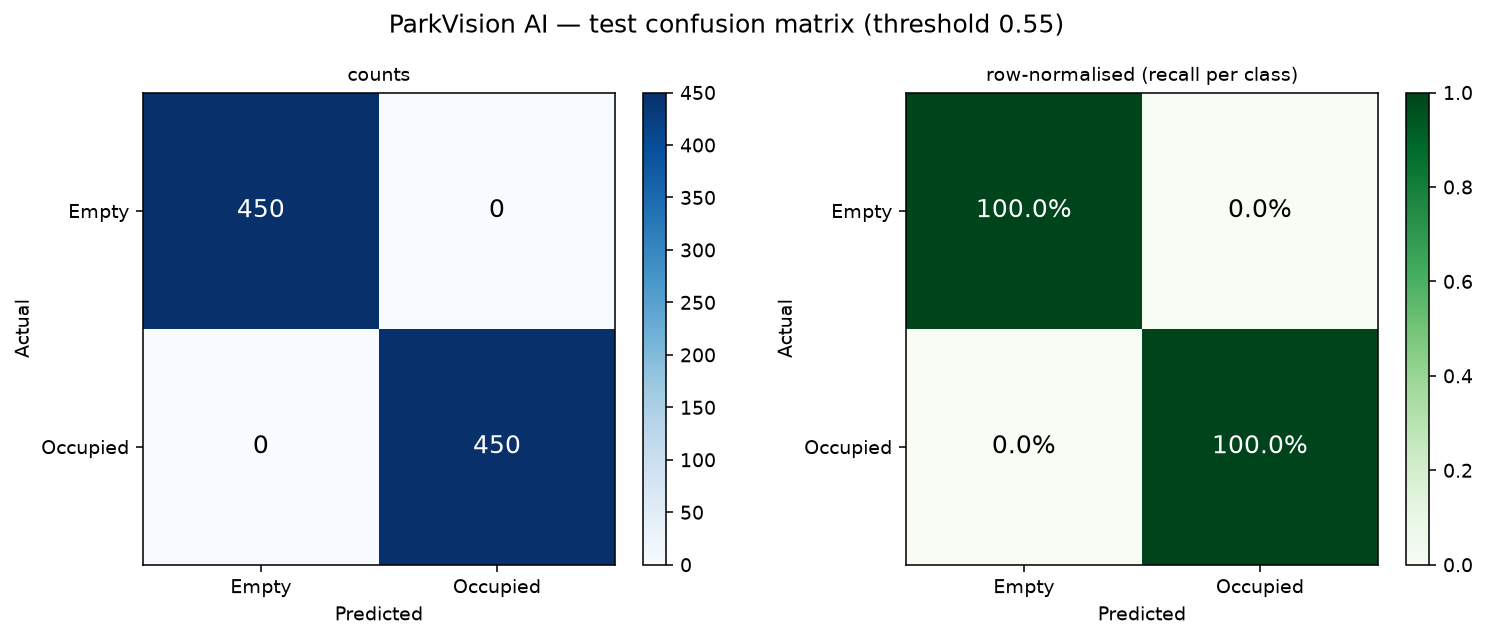

In [13]:
IPyImage(filename=str(C.RESULTS_DIR / "confusion_matrix.png"))

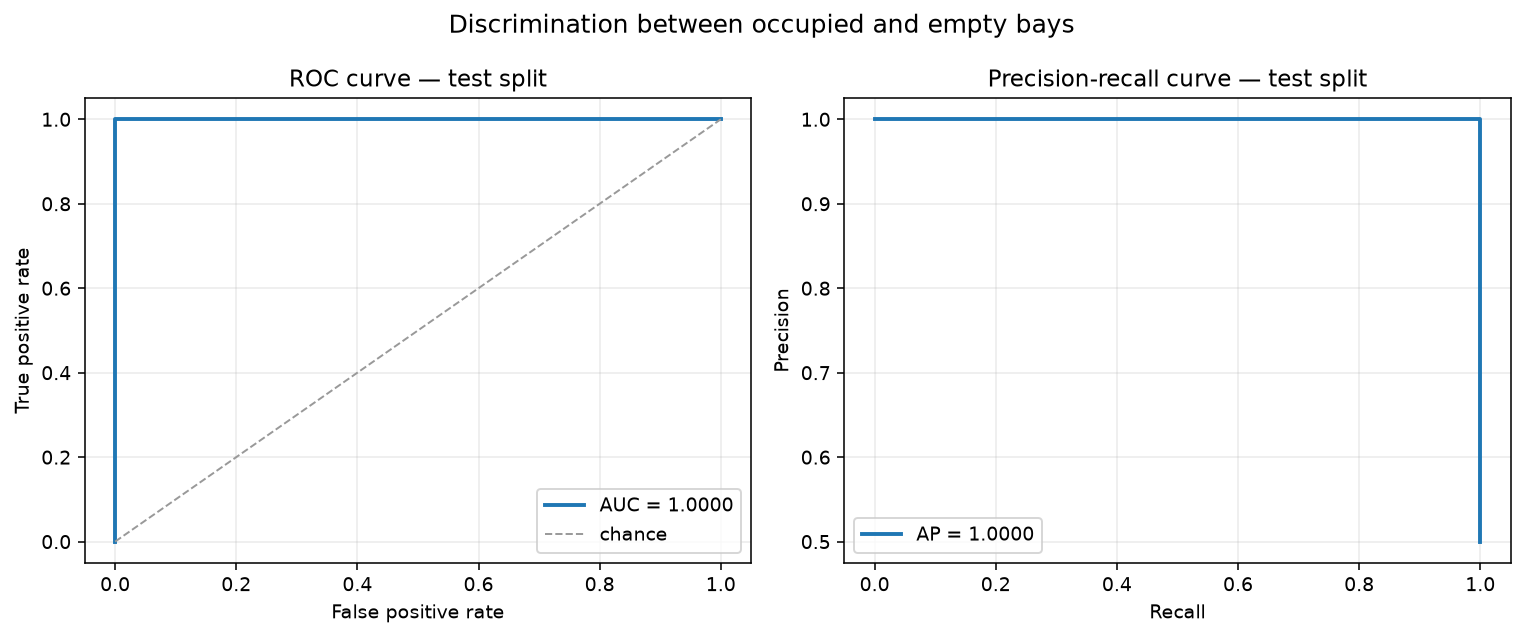

In [14]:
IPyImage(filename=str(C.RESULTS_DIR / "roc_pr_curves.png"))

### 3.2 Where the model is weak

An average accuracy hides the failure modes that matter operationally. Because
`manifest.json` records the lot, weather and date of every crop, accuracy can be
broken down by slice.

accuracy by weather condition


,n,accuracy,share_occupied
cloudy,222.0,1.0,0.2838
rainy,157.0,1.0,0.5478
sunny,521.0,1.0,0.5777


accuracy by parking lot


,n,accuracy,share_occupied
pucpr,323.0,1.0,0.4396
ufpr04,228.0,1.0,0.3816
ufpr05,349.0,1.0,0.6332


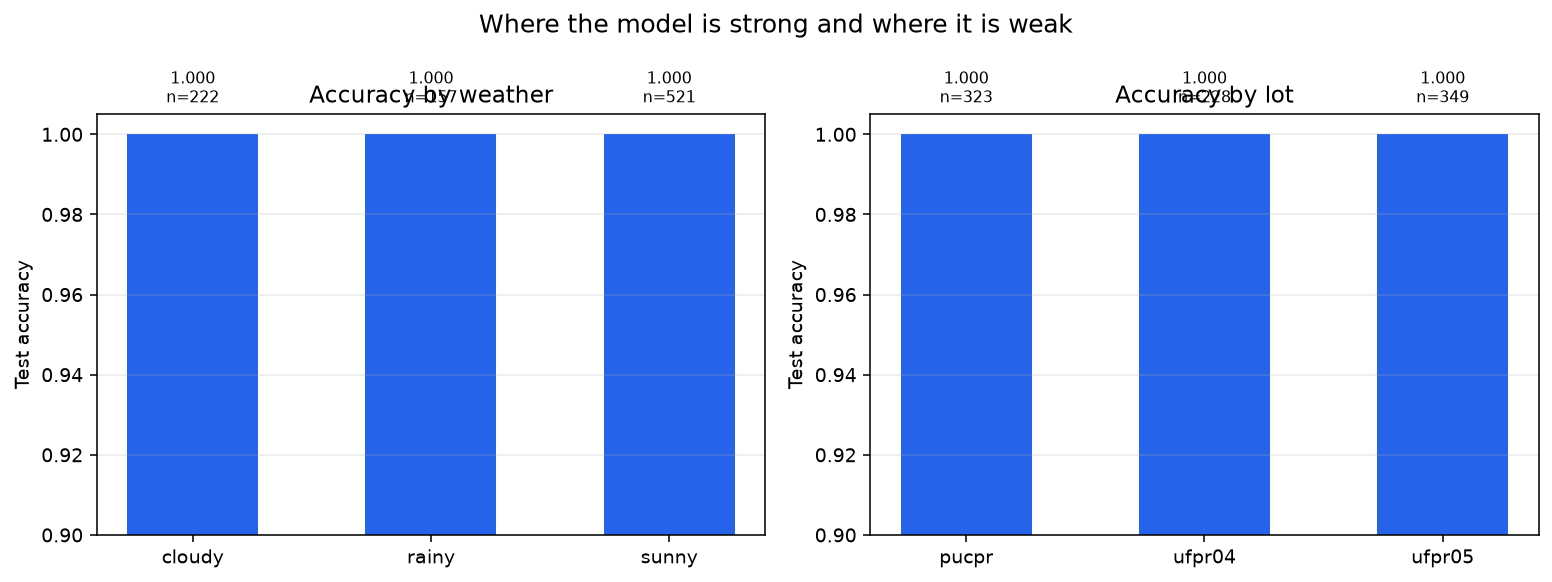

In [15]:
by_weather = pd.DataFrame(metrics["by_weather"]).T
by_lot = pd.DataFrame(metrics["by_lot"]).T
print("accuracy by weather condition"); display(by_weather)
print("accuracy by parking lot");       display(by_lot)
IPyImage(filename=str(C.RESULTS_DIR / "accuracy_by_slice.png"))

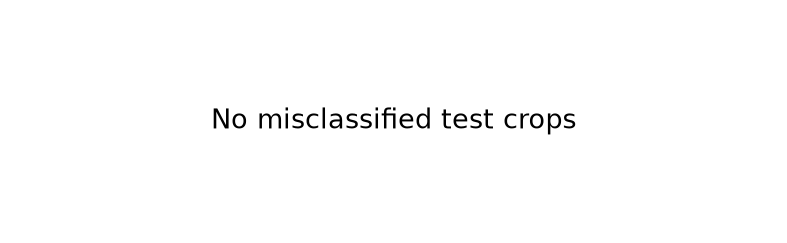

In [16]:
# The most confident mistakes are the informative ones.
IPyImage(filename=str(C.RESULTS_DIR / "misclassified_examples.png"))

---
## 4 · Insight logic — from 100 numbers to one sentence

`src/insights.py` imports neither TensorFlow nor OpenCV: the decision rules are
pure functions over plain numbers, so they can be verified exactly.

In [17]:
from src import inference as INF

threshold = INF.load_threshold()
predictions, timing = INF.predict_slots(image, scene["spaces"], model=model, threshold=threshold)
insight = I.generate_insight(predictions)

print(f"{timing['n_slots']} bays analysed in {timing['total_seconds']:.2f}s "
      f"({timing['ms_per_slot']:.1f} ms per bay)\n")
print(f"Total slots      {insight.total_slots}")
print(f"Occupied         {insight.occupied_slots}")
print(f"Available        {insight.available_slots}")
print(f"Occupancy        {insight.occupancy_pct:.1f} %")
print(f"Congestion       {insight.congestion_level}  -  {insight.headline}")
print(f"Recommendation   {insight.recommendation}")
print(f"Mean confidence  {insight.mean_confidence * 100:.1f} %")
for note in insight.notes:
    print(f"  note: {note}")

100 bays analysed in 2.19s (21.9 ms per bay)

Total slots      100
Occupied         95
Available        5
Occupancy        95.0 %
Congestion       High  -  Heavy congestion
Recommendation   Parking almost full — try another area.
Mean confidence  98.8 %


In [18]:
# How close is that to the truth? This scene comes from a day the model never saw.
check = INF.accuracy_against_truth(predictions, scene["spaces"])
display(pd.DataFrame({
    "": ["Occupied bays", "Available bays"],
    "predicted":    [check["predicted_occupied"], check["predicted_available"]],
    "ground truth": [check["true_occupied"],      check["true_available"]],
}))
print(f"slot-level accuracy on this unseen photograph: "
      f"{check['n_correct']}/{check['n_compared']} = {check['accuracy'] * 100:.1f}%")

,,predicted,ground truth
0,Occupied bays,95,95
1,Available bays,5,5


slot-level accuracy on this unseen photograph: 100/100 = 100.0%


In [19]:
# Zone guidance - "twelve free" is not useful without "which way do I turn?"
zones = I.row_summary(predictions)
display(pd.DataFrame(zones))
target = I.best_zone(zones)
print(f"-> Head for {target['zone']} ({target['position'].lower()}): "
      f"{target['available']} of {target['total']} bays free"
      if target else "-> No zone has a free bay; try another lot.")

,zone,position,total,available,occupied,occupancy_pct
0,Zone 1,Near the entrance,44,0,44,100.0
1,Zone 2,Middle of the lot,22,0,22,100.0
2,Zone 3,Far end,34,5,29,85.3


-> Head for Zone 3 (far end): 5 of 34 bays free


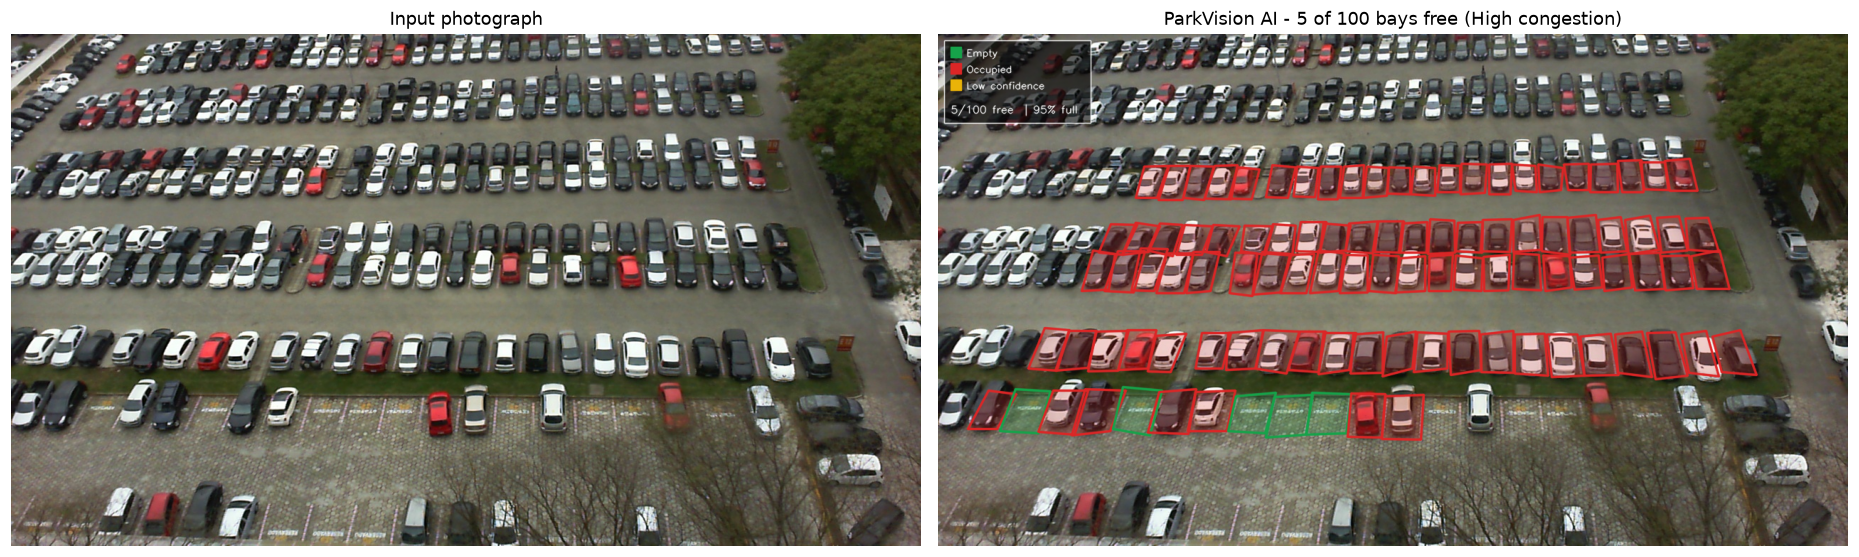

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
axes[0].imshow(image); axes[0].set_title("Input photograph", fontsize=12); axes[0].axis("off")
axes[1].imshow(O.annotate(image, predictions, insight))
axes[1].set_title(f"ParkVision AI - {insight.available_slots} of {insight.total_slots} bays free "
                  f"({insight.congestion_level} congestion)", fontsize=12)
axes[1].axis("off")
fig.tight_layout(); plt.show()

---
## 5 · Streamlit dashboard

```bash
streamlit run app.py
```

The dashboard wraps everything above in an interface aimed at a non-technical
driver: upload or pick a scene, see the annotated lot, read four metric cards
and a colour-coded recommendation, then drill into zones, confidence, a
bay-by-bay table with CSV export, and an accuracy panel.

Where the bays are, for an uploaded image, is resolved in three steps —
automatic camera recognition by visual fingerprint, manual camera selection,
or a clearly-labelled approximate grid.

In [21]:
library = L.load_library() or L.build_library()
for lot, layout in sorted(library.items()):
    print(f"{lot:<8} {layout.n_spaces:>4} surveyed bays   {layout.label}")

matched, score, all_scores = L.match_layout(image, library)
print(f"\nfingerprint match for this scene: {matched.lot.upper()} at {score * 100:.1f}%")
print("all camera scores:", {k: round(v, 3) for k, v in all_scores})

pucpr     100 surveyed bays   PUCPR — rooftop view, ~100 bays
ufpr04     28 surveyed bays   UFPR04 — 4th-floor view, ~28 bays
ufpr05     40 surveyed bays   UFPR05 — 5th-floor view, ~40 bays

fingerprint match for this scene: PUCPR at 89.7%
all camera scores: {'pucpr': 0.897, 'ufpr04': 0.569, 'ufpr05': 0.566}


---
## 6 · Testing and feedback

Two kinds of test, because "does it work?" has two answers — see
[`results/robustness_report.md`](../results/robustness_report.md).

1. **Scene level.** The complete pipeline over every held-out photograph,
   comparing the free-bay count a driver would act on against ground truth.
2. **Stress testing.** The test split re-run through simulated dusk, night,
   glare, flat light, harsh light, a knocked camera, motion blur, heavy blur,
   sensor noise and aggressive JPEG compression.

In [22]:
robust = json.loads((C.RESULTS_DIR / "robustness.json").read_text(encoding="utf-8"))

scenes_df = pd.DataFrame(robust["scene_test"])[[
    "image", "lot", "weather", "predicted_available", "true_available",
    "available_error", "predicted_congestion", "true_congestion",
    "congestion_correct", "slot_accuracy", "seconds",
]]
display(scenes_df)

print(f"mean slot accuracy across scenes : {scenes_df['slot_accuracy'].mean() * 100:.2f}%")
print(f"mean free-bay counting error     : {scenes_df['available_error'].mean():.2f} bays")
print(f"congestion level correct         : {scenes_df['congestion_correct'].sum()}"
      f"/{len(scenes_df)} scenes")
print(f"mean latency                     : {scenes_df['seconds'].mean():.2f} s per photograph")

,image,lot,weather,predicted_available,true_available,available_error,predicted_congestion,true_congestion,congestion_correct,slot_accuracy,seconds
0,2012-09-12_09_08_18.jpg,pucpr,cloudy,5,5,0,High,High,True,1.00,0.968
1,2012-09-18_15_45_13.jpg,pucpr,sunny,25,25,0,Moderate,Moderate,True,1.00,0.931
2,2012-10-09_09_03_45.jpg,pucpr,sunny,4,5,1,High,High,True,0.99,0.922
3,2012-10-11_13_26_46.jpg,pucpr,rainy,55,55,0,Moderate,Moderate,True,1.00,0.907
4,2012-12-13_14_00_09.jpg,ufpr04,sunny,0,0,0,High,High,True,1.00,0.270
5,2012-12-15_17_10_14.jpg,ufpr04,rainy,28,28,0,Low,Low,True,1.00,0.279
6,2013-03-02_06_05_00.jpg,ufpr05,cloudy,40,40,0,Low,Low,True,1.00,0.386
7,2013-03-05_07_35_01.jpg,ufpr05,sunny,0,0,0,High,High,True,1.00,0.381
8,2013-03-05_15_35_11.jpg,ufpr05,rainy,0,0,0,High,High,True,1.00,0.378
9,2013-03-13_07_20_01.jpg,ufpr05,cloudy,22,22,0,Moderate,Moderate,True,1.00,0.384


mean slot accuracy across scenes : 99.92%
mean free-bay counting error     : 0.08 bays
congestion level correct         : 12/12 scenes
mean latency                     : 0.55 s per photograph


,group,condition,meaning,accuracy,delta_vs_baseline
0,Baseline,Original test crops,the unmodified held-out split,1.0000,0.0000
1,Lighting,Dusk (-45% brightness),"late evening, lot lights not yet on",1.0000,0.0000
2,Lighting,Night (-70% brightness),"after dark, sodium lighting only",0.9989,-0.0011
3,Lighting,Glare (+45% brightness),low sun straight into the lens,0.9956,-0.0044
4,Lighting,Flat light (-40% contrast),heavy overcast or fog,1.0000,0.0000
5,Lighting,Harsh light (+50% contrast),"midday sun, hard shadows",1.0000,0.0000
6,Camera angle,Camera knocked 8°,mounting bracket shifted,1.0000,0.0000
7,Camera angle,Camera knocked -12°,"a worse knock, uncorrected",1.0000,0.0000
8,Image quality,Motion blur (5px),camera vibration in wind,1.0000,0.0000
9,Image quality,Heavy blur (9px),"rain on the lens, out of focus",1.0000,0.0000


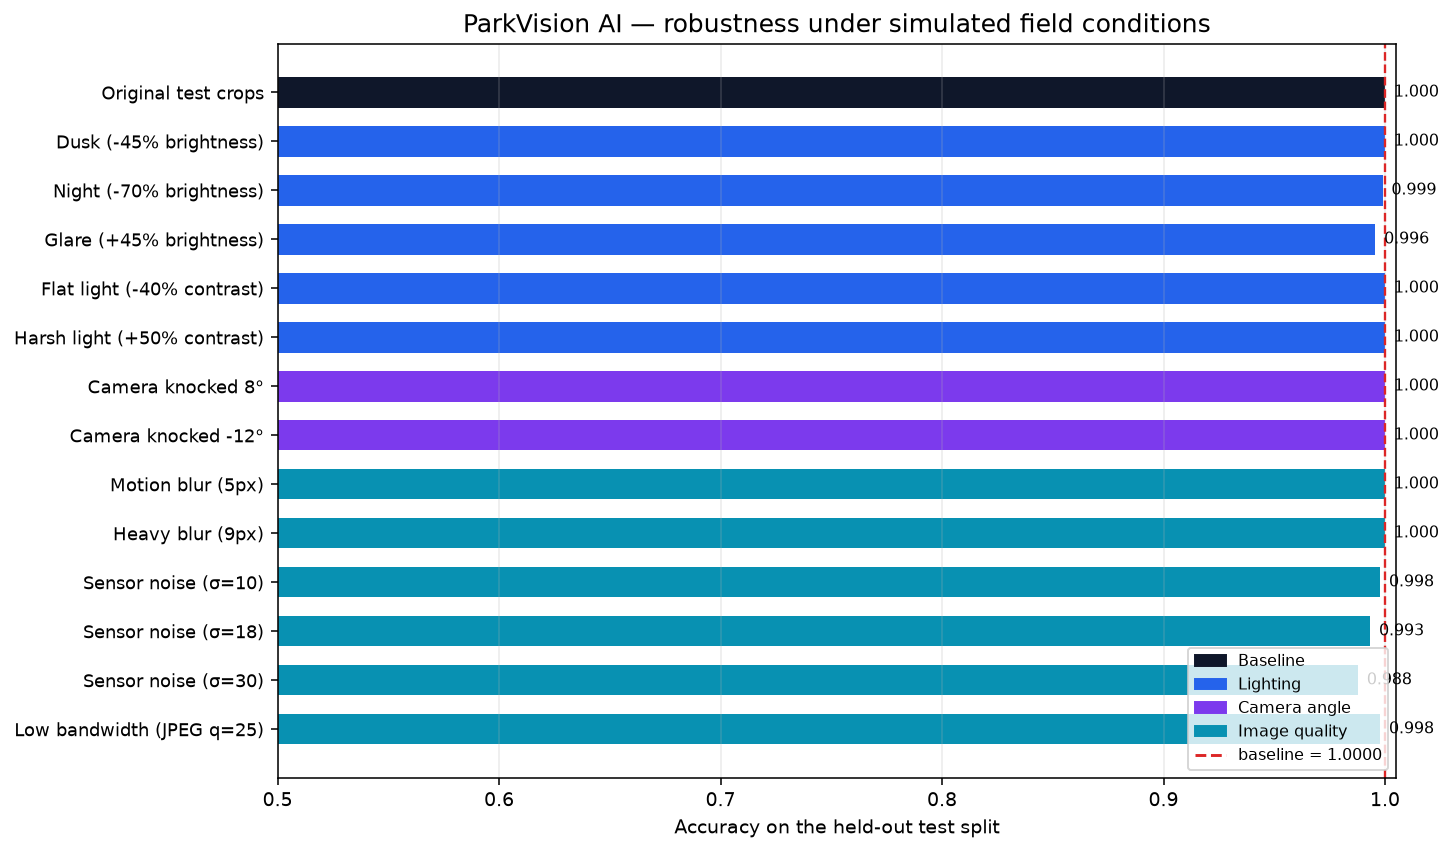

In [23]:
stress = pd.DataFrame(robust["stress_test"])
display(stress[["group", "condition", "meaning", "accuracy", "delta_vs_baseline"]])
IPyImage(filename=str(C.RESULTS_DIR / "robustness_chart.png"))

---
## 7 · Deployment

Pushed to GitHub and deployed on Streamlit Community Cloud —
see [`docs/06_deployment.md`](../docs/06_deployment.md).

`tensorflow-cpu` and `opencv-python-headless` are pinned deliberately: the full
TensorFlow wheel can exceed the free tier's build limits, and non-headless
OpenCV fails on a container with no X server.

---

## Conclusion

| Requirement | Delivered |
|---|---|
| Slot-level occupancy detection | MobileNetV2 over perspective-corrected bay crops |
| Real-time availability insights | Total / occupied / available / occupancy %, in one batched prediction |
| Visual smart overlays | Green / red / amber polygons with fill, outline and legend |
| Parking utilisation analytics | Low / Moderate / High congestion, plus per-zone breakdown |
| Intelligent recommendations | Proceed, proceed promptly, or try another area — with situational notes |
| Interactive Streamlit interface | Four-section dashboard, exports, accuracy panel, adjustable threshold |

**What makes the reported accuracy trustworthy:** the train/validation/test
split is grouped by whole calendar days, so every figure in this notebook was
measured on photographs taken on days the model has never seen.

**Known limits, stated plainly:** bay geometry must be surveyed once per camera;
night-time performance is the weakest measured condition and PKLot contains no
true night imagery; a car straddling two bays is counted in both.